# PROJECT THỰC HÀNH PYTHON
## Quản lý điểm sinh viên và tạo Web App

**Họ tên:** ...  
**MSSV:** ...

In [1]:
#0. Import thư viện
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#1. Tạo DataFrame chứa thông tin 10 sinh viên
df = pd.DataFrame({
    "Ho_ten": ["Nguyễn Văn An", "Trần Thị Bình", "Lê Minh Chi", "Phạm Quốc Dũng", "Hoàng Thu Hà",
               "Vũ Ngọc Lan", "Đặng Hoàng Minh", "Bùi Thành Nam", "Đỗ Hồng Phúc", "Ngô Thùy Trang"],
    "Chuyen_can": [9, 10, 8, 10, 9, 7, 10, 8, 9, 10],
    "Giua_ky":    [7.5, 8, 6, 9, 7, 4.5, 8.5, 7, 7.5, 9.5],
    "Cuoi_ky":    [7.5, 8, 5.5, 9, 7, 3.5, 9, 6.5, 7, 9],
})

# Hiển thị bảng dữ liệu
df

,Ho_ten,Chuyen_can,Giua_ky,Cuoi_ky
0,Nguyễn Văn An,9,7.5,7.5
1,Trần Thị Bình,10,8.0,8.0
2,Lê Minh Chi,8,6.0,5.5
3,Phạm Quốc Dũng,10,9.0,9.0
4,Hoàng Thu Hà,9,7.0,7.0
5,Vũ Ngọc Lan,7,4.5,3.5
6,Đặng Hoàng Minh,10,8.5,9.0
7,Bùi Thành Nam,8,7.0,6.5
8,Đỗ Hồng Phúc,9,7.5,7.0
9,Ngô Thùy Trang,10,9.5,9.0


In [3]:
#2. Tính điểm tổng kết
# Tổng kết = 20% Chuyên cần + 30% Giữa kỳ + 50% Cuối kỳ
df["Tong_ket"] = (0.2 * df["Chuyen_can"] + 0.3 * df["Giua_ky"] + 0.5 * df["Cuoi_ky"]).round(2)
df

,Ho_ten,Chuyen_can,Giua_ky,Cuoi_ky,Tong_ket
0,Nguyễn Văn An,9,7.5,7.5,7.80
1,Trần Thị Bình,10,8.0,8.0,8.40
2,Lê Minh Chi,8,6.0,5.5,6.15
3,Phạm Quốc Dũng,10,9.0,9.0,9.20
4,Hoàng Thu Hà,9,7.0,7.0,7.40
5,Vũ Ngọc Lan,7,4.5,3.5,4.50
6,Đặng Hoàng Minh,10,8.5,9.0,9.05
7,Bùi Thành Nam,8,7.0,6.5,6.95
8,Đỗ Hồng Phúc,9,7.5,7.0,7.55
9,Ngô Thùy Trang,10,9.5,9.0,9.35


In [4]:
#3. Xếp loại sinh viên
def xep_loai(diem):
    if diem >= 8.5:
        return "Giỏi"
    elif diem >= 7.0:
        return "Khá"
    elif diem >= 5.0:
        return "Trung bình"
    else:
        return "Yếu"

df["Xep_loai"] = df["Tong_ket"].apply(xep_loai)
df

,Ho_ten,Chuyen_can,Giua_ky,Cuoi_ky,Tong_ket,Xep_loai
0,Nguyễn Văn An,9,7.5,7.5,7.80,Khá
1,Trần Thị Bình,10,8.0,8.0,8.40,Khá
2,Lê Minh Chi,8,6.0,5.5,6.15,Trung bình
3,Phạm Quốc Dũng,10,9.0,9.0,9.20,Giỏi
4,Hoàng Thu Hà,9,7.0,7.0,7.40,Khá
5,Vũ Ngọc Lan,7,4.5,3.5,4.50,Yếu
6,Đặng Hoàng Minh,10,8.5,9.0,9.05,Giỏi
7,Bùi Thành Nam,8,7.0,6.5,6.95,Trung bình
8,Đỗ Hồng Phúc,9,7.5,7.0,7.55,Khá
9,Ngô Thùy Trang,10,9.5,9.0,9.35,Giỏi


In [5]:
#4. Thống kê
diem_tb = round(df["Tong_ket"].mean(), 2)
sv_cao_nhat = df.loc[df["Tong_ket"].idxmax()]
sv_thap_nhat = df.loc[df["Tong_ket"].idxmin()]
so_sv_dat = (df["Tong_ket"] >= 5).sum()

print("Điểm tổng kết trung bình của lớp:", diem_tb)
print(f"Sinh viên điểm cao nhất: {sv_cao_nhat['Ho_ten']} ({sv_cao_nhat['Tong_ket']})")
print(f"Sinh viên điểm thấp nhất: {sv_thap_nhat['Ho_ten']} ({sv_thap_nhat['Tong_ket']})")
print(f"Số sinh viên đạt (>= 5): {so_sv_dat}/{len(df)}")

Điểm tổng kết trung bình của lớp: 7.64
Sinh viên điểm cao nhất: Ngô Thùy Trang (9.35)
Sinh viên điểm thấp nhất: Vũ Ngọc Lan (4.5)
Số sinh viên đạt (>= 5): 9/10


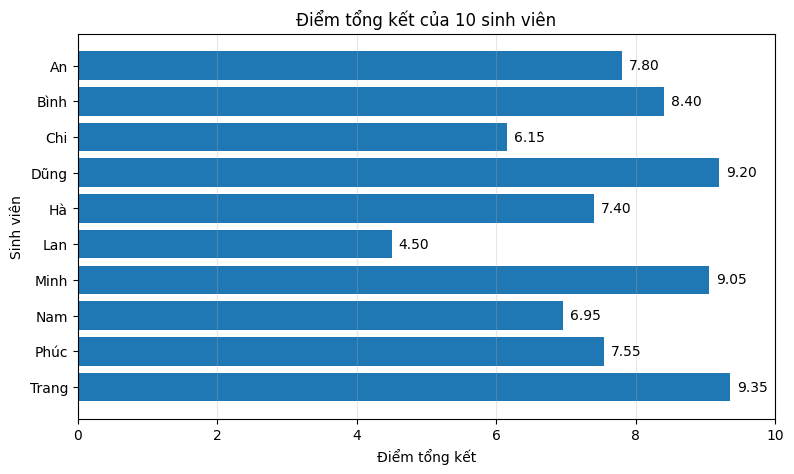

In [6]:
#5. Trực quan hóa: biểu đồ cột điểm tổng kết của 10 sinh viên
ten = df["Ho_ten"].str.split().str[-1]   # lấy tên (từ cuối) cho gọn

plt.figure(figsize=(9, 5))
plt.barh(ten, df["Tong_ket"])
plt.gca().invert_yaxis()                  # SV đầu danh sách nằm trên cùng
plt.title("Điểm tổng kết của 10 sinh viên")
plt.xlabel("Điểm tổng kết")
plt.ylabel("Sinh viên")
plt.xlim(0, 10)
for i, d in enumerate(df["Tong_ket"]):
    plt.text(d + 0.1, i, f"{d:.2f}", va="center")
plt.grid(axis="x", alpha=0.3)
plt.show()